## Семинар 8: Seq2seq. Attention

На этом семинаре мы рассмотрим задачу Seq2seq и решим задачу машинного перевода с помощью рекуррентных сетей и с помощью механизма Attention.


In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch import optim
from torch.utils.data import Dataset, DataLoader
import os
import random
import numpy as np
import re
import math
from typing import Tuple

from tqdm.auto import tqdm

import matplotlib
matplotlib.rcParams['figure.figsize'] = (10, 6)

import matplotlib.pyplot as plt


def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True

seed_everything()
device = torch.device('cuda')

### Почему RNN?

#### Обычные нейросети:
- Принимают фиксированный размер на вход, выдают фиксированный размер на выход.

#### Рекуррентные нейросети:
- Оперируют последовательностями -- на вход любого размера последовательность, на выход так же.

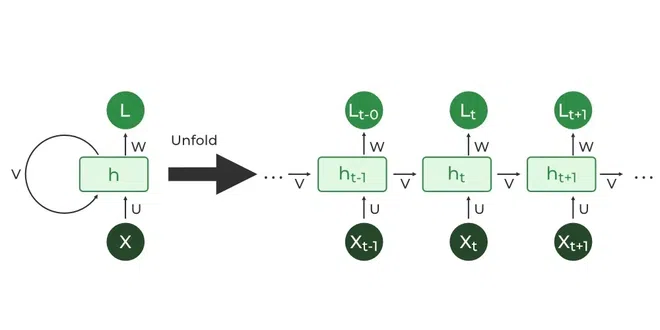

Даже если ваши данные выглядят не вполне как последовательности, чаще всего вы можете переформулировать задачу, представить свои данные в соответствующем виде, и обработать ее как последовательность.

### Так и как они работают?

Очень просто. Можно сказать, обманчиво просто.

```
rnn = RNN()
y, _ = rnn(x)
```
Вектор на вход, вектор на выход. Что важно? Что `y` зависит не только от `x`, но еще и от всех предыдущих входов, которые вы передали ранее.

На сегодняшнем семинаре бы будем использовать `GRU` вместо обычной `RNN`, что сложнее в нюансах, но концептуально реализует ту же самую идею.

Приведем простой пример использования `RNN` для генерации текста, для того чтобы проиллюстрировать что происходит внутри `RNN`ки.
Обучим простую `RNN` генерировать текст, используя единственный тренировочный пример "hello".


In [4]:
# Наши "данные"
data = "hello"

In [5]:
# Соответствующий словарь, которым сможет оперировать модель
chars = ['h', 'e', 'l', 'o']

In [6]:
# Для упрощения жизни, сделаем пару словарей чтобы переводить из букв в числа и назад
char_to_idx = {ch: i for i, ch in enumerate(chars)}
idx_to_char = {i: ch for i, ch in enumerate(chars)}

In [7]:
# Накидаем каких-нибудь гиперпараметров
hidden_size = 5 #скрытое состояние
embedding_dim = 5 #размерность вектора, хранящего информацию о токене
learning_rate = 0.005
num_epochs = 150



## Напишем forward у сети

In [8]:
import torch
import torch.nn as nn
from typing import Tuple

# Напишем простейшую модель
class GRUModel(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_size, output_size):
        """
        vocab_size:    размер словаря (количество уникальных токенов)
        embedding_dim: размерность векторного представления каждого слова
        hidden_size:   размерность скрытого состояния (памяти) GRU
        output_size:   размерность выхода (например, количество классов для предсказания)
        """
        super(GRUModel, self).__init__()

        self.hidden_size = hidden_size

        # Слой эмбеддингов: преобразует индексы слов в плотные векторы заданной размерности
        self.embedding = nn.Embedding(num_embeddings=vocab_size, embedding_dim=embedding_dim)

        # Рекуррентный слой GRU: обрабатывает последовательность векторов, обновляя скрытое состояние
        self.gru = nn.GRU(input_size=embedding_dim, hidden_size=hidden_size, num_layers=1)

        # Полносвязный слой (Linear): проецирует скрытое состояние GRU на итоговое пространство ответов
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, input, hidden) -> Tuple[torch.Tensor, torch.Tensor]:
        """
        input:  тензор с индексами входных слов (например, одно слово/токен)
        hidden: тензор скрытого состояния с предыдущего шага
        """
        # 1. Извлекаем эмбеддинг для входного токена и меняем его форму.
        # Метод view(1, 1, -1) приводит тензор к формату (seq_len=1, batch_size=1, embedding_dim),
        # так как nn.GRU по умолчанию ожидает именно такую последовательность размерностей.
        embedding = self.embedding(input).view(1, 1, -1)

        # 2. Пропускаем эмбеддинг и прошлое скрытое состояние через ячейку GRU.
        # output содержит выходы GRU для всех шагов последовательности,
        # hidden — финальное скрытое состояние после обработки всей последовательности.
        output, hidden = self.gru(embedding, hidden)

        # 3. Убираем первую размерность (seq_len=1) с помощью squeeze(0),
        # чтобы передать вектор скрытого состояния в полносвязный слой.
        out = self.fc(output.squeeze(0))

        # Возвращаем предсказание модели и обновленное скрытое состояние для следующего шага
        return out, hidden

    def init_hidden(self):
        """
        Метод для инициализации самого первого скрытого состояния (вектора памяти) нулями.
        Формат тензора: (num_layers=1, batch_size=1, hidden_size)
        """
        return torch.zeros(1, 1, self.hidden_size)

In [9]:

#Переведем данные в вид, в котором их сможет кушать модель
input_seq = torch.tensor([char_to_idx[ch] for ch in data[:-1]], dtype=torch.long)
target_seq = torch.tensor([char_to_idx[ch] for ch in data[1:]], dtype=torch.long)

In [10]:
# Инициализируем модель, лосс и оптимизатор
model = GRUModel(len(chars), embedding_dim, hidden_size, len(chars))
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

In [11]:
# Функция для того чтобы смотреть что получается
def predict(model, character, hidden=None):
    input = torch.tensor([char_to_idx[character]], dtype=torch.long)
    if hidden is None:
        hidden = model.init_hidden()
    output, hidden = model(input, hidden)
    output = F.softmax(output, dim=1)
    _, top_i = output.topk(1)
    return idx_to_char[top_i.item()], output, hidden

def print_var(output, char):
    prob_char = idx_to_char[output.topk(1).indices.detach().item()]
    print("Наиболее вероятный следующий символ:", prob_char)
    print(
        f"""
        Prob of 'h' after '{char}': {output[0][0]:.2f}
        Prob of 'e' after '{char}': {output[0][1]:.2f}
        Prob of 'l' after '{char}': {output[0][2]:.2f}
        Prob of 'o' after '{char}': {output[0][3]:.2f}
        """)

In [12]:
import torch
import torch.nn.functional as F

# Начинаем цикл обучения по эпохам
for epoch in range(num_epochs):
    # Перед началом новой последовательности (эпохи) инициализируем скрытое состояние нулями.
    # Это "очищает память" модели, чтобы контекст прошлой эпохи не влиял на текущую.
    hidden = model.init_hidden()

    # Обнуляем градиенты оптимизатора, чтобы градиенты с прошлой эпохи не складывались с новыми.
    optimizer.zero_grad()

    # Инициализируем переменную для накопления функции потерь за всю последовательность
    loss = 0

    # Добавляем размерность батча (batch_size=1) во вторую позицию.
    # Из (seq_len) получаем форму (seq_len, 1), так как GRU ожидает (seq_len, batch, input_size).
    input_data = input_seq.unsqueeze(1)

    # Посимвольно/пословесно перебираем всю входную последовательность
    for i in range(input_data.size(0)):
        # Передаем текущий элемент последовательности input_data[i] (размерность 1)
        # и текущую память hidden. На выходе получаем предсказание и обновленный hidden.
        output, hidden = model(input_data[i], hidden)

        # Считаем ошибку для текущего шага и прибавляем её к общей сумме loss.
        # target_seq[i].unsqueeze(0) добавляет размерность батча, чтобы соответствовать форме output.
        loss += loss_fn(output, target_seq[i].unsqueeze(0))

    # Обратный проход: вычисляем градиенты для всех весов модели на основе суммарного loss
    loss.backward()

    # Обновляем веса модели (делаем шаг градиентного спуска)
    optimizer.step()

    # Каждые 10 эпох выводим промежуточные результаты и делаем тестовое предсказание
    if epoch % 10 == 0:
        # Печатаем средний loss на один символ в этой эпохе (суммарный loss делим на длину последовательности)
        print(f'Epoch {epoch}: Loss: {loss.item() / input_data.size(0)}')

        # Проверяем, как модель предсказывает: подаем на вход первый символ (например, 'h')
        input_test = torch.tensor([char_to_idx['h']], dtype=torch.long)

        # Снова инициализируем чистую память для генерации теста
        hidden = model.init_hidden()

        # Делаем один шаг предсказания на тестовом символе
        output, hidden = model(input_test, hidden)

        # Превращаем сырые выходы модели (логиты) в вероятности с помощью Softmax
        output = F.softmax(output, dim=1)

        # Отвязываем тензор от графа вычислений (градиенты для теста нам не нужны)
        preds = output.detach()

        # Кастомная функция (или встроенная у вас) для вывода/визуализации полученных вероятностей
        print_var(preds, 'h')


Epoch 0: Loss: 1.511156439781189
Наиболее вероятный следующий символ: h

        Prob of 'h' after 'h': 0.37
        Prob of 'e' after 'h': 0.17
        Prob of 'l' after 'h': 0.25
        Prob of 'o' after 'h': 0.21
        
Epoch 10: Loss: 1.3404940366744995
Наиболее вероятный следующий символ: h

        Prob of 'h' after 'h': 0.30
        Prob of 'e' after 'h': 0.21
        Prob of 'l' after 'h': 0.29
        Prob of 'o' after 'h': 0.19
        
Epoch 20: Loss: 1.1928983926773071
Наиболее вероятный следующий символ: l

        Prob of 'h' after 'h': 0.25
        Prob of 'e' after 'h': 0.25
        Prob of 'l' after 'h': 0.33
        Prob of 'o' after 'h': 0.17
        
Epoch 30: Loss: 1.0325168371200562
Наиболее вероятный следующий символ: l

        Prob of 'h' after 'h': 0.21
        Prob of 'e' after 'h': 0.29
        Prob of 'l' after 'h': 0.35
        Prob of 'o' after 'h': 0.15
        
Epoch 40: Loss: 0.8548879623413086
Наиболее вероятный следующий символ: e

        Prob of

Видим, что вероятность получить **"e"** после **"h"** растет с каждой итерацией обучения. Но как быть с **"l"**? Иногда после **"l"** идет **"o"**, иногда другая **"l"**. За это отвечает скрытое состояние, в котором хранится информация о прошлом, и по которому модель понимает, какой символ выбрать.

Спросим у модели, какой символ идет после символа **"l"**.

In [13]:
char, output, hidden = predict(model, 'l', hidden=None) #пустой контекст
print("Наиболее вероятный следующий символ:", char)
print(
    f"""
    Prob of 'h' after 'l': {output[0][0]:.2f}
    Prob of 'e' after 'l': {output[0][1]:.2f}
    Prob of 'l' after 'l': {output[0][2]:.2f}
    Prob of 'o' after 'l': {output[0][3]:.2f}
    """)

Наиболее вероятный следующий символ: o

    Prob of 'h' after 'l': 0.10
    Prob of 'e' after 'l': 0.13
    Prob of 'l' after 'l': 0.06
    Prob of 'o' after 'l': 0.72
    


Модель считает, что без контекста скорее **"o"**.
Теперь дадим ей немного контекста.

In [14]:
char, output, hidden = predict(model, 'e', hidden=None) # это будет нашим контекстом
print("Наиболее вероятный следующий символ:", char)
print(
    f"""
    Prob of 'h' after 'e': {output[0][0]:.2f}
    Prob of 'e' after 'e': {output[0][1]:.2f}
    Prob of 'l' after 'e': {output[0][2]:.2f}
    Prob of 'o' after 'e': {output[0][3]:.2f}
    """)

Наиболее вероятный следующий символ: l

    Prob of 'h' after 'e': 0.01
    Prob of 'e' after 'e': 0.03
    Prob of 'l' after 'e': 0.95
    Prob of 'o' after 'e': 0.01
    


In [15]:
char, output, hidden = predict(model, 'l', hidden) #здесь мы передали выход hidden с предыдущей ячейки
print("Наиболее вероятный следующий символ:", char)
print(
    f"""
    Prob of 'h' after 'l': {output[0][0]:.2f}
    Prob of 'e' after 'l': {output[0][1]:.2f}
    Prob of 'l' after 'l': {output[0][2]:.2f}
    Prob of 'o' after 'l': {output[0][3]:.2f}
    """)

Наиболее вероятный следующий символ: l

    Prob of 'h' after 'l': 0.02
    Prob of 'e' after 'l': 0.01
    Prob of 'l' after 'l': 0.89
    Prob of 'o' after 'l': 0.08
    


Помимо вопроса "Какой символ будет после **"l"**?" мы передали информацию, что перед этой **"l"** был символ **"e"**. Зная это, модель меняет свое первоначальное предсказание, и дает верный ответ.

Таким образом, через `hidden_state` модель и поддерживает глобальный контекст, запоминая и используя релевантную информацию из прошлого.

### 1. Предобработка и подготовка данных.

Решать будем задачу **NMT**: **Neural Machine Translation**. Для этого нам понадобятся данные: симметричные пары фраз на разных языках. Будем учиться переводить с французского на английский, а в качестве составных конструкций **(токенов)** фраз будем брать уже не просто буквы, как в предыдущем примере, а целые слова.

In [16]:
!pip install tatoebatools

In [17]:
import unicodedata
from tatoebatools import ParallelCorpus

In [18]:
freng_corp = list(ParallelCorpus('fra', 'eng'))

100%|██████████| 2.66M/2.66M [00:00<00:00, 2.78MiB/s]
100%|██████████| 14.8M/14.8M [00:01<00:00, 7.67MiB/s]
100%|██████████| 34.9M/34.9M [00:02<00:00, 11.9MiB/s]


In [19]:
print ('Number of phrases = ', len(freng_corp))
for x in freng_corp[::50000]:
    print('French: ', x[0].text)
    print('English:', x[1].text, end='\n\n')

Number of phrases =  440683
French:  Lorsqu'il a demandé qui avait cassé la fenêtre, tous les garçons ont pris un air innocent.
English: When he asked who had broken the window, all the boys put on an air of innocence.

French:  Il avait marché durant des heures.
English: It had worked for hours.

French:  Elle aime les nouvelles expériences.
English: She likes new experiences.

French:  Tu trouves que c'est normal de parler comme ça ?!
English: Do you think it's normal to talk like that?

French:  Vous m'avez tellement manqué !
English: I missed you so much!

French:  Dès que je termine, je sors.
English: As soon as I finish, I am going out.

French:  Ce n'est pas à moi d'en décider.
English: That isn't for me to decide.

French:  Sais-tu compter jusqu'à cent en français ?
English: Can you count to one hundred in French?

French:  Tu vas t'électrocuter si tu ne fais pas plus attention.
English: You're going to electrocute yourself if you aren't more careful.



In [20]:
# Константы для специальных токенов:
SOS_token = 0  # Start Of Sentence — маркер начала предложения (используется для запуска генерации)
EOS_token = 1  # End Of Sentence — маркер конца предложения (сигнализирует модели о завершении генерации)

class Lang:
    def __init__(self, name):
        """
        Класс для управления словарем одного языка.
        name: название языка (например, 'eng' или 'rus')
        """
        self.name = name
        self.word2index = {}  # Словарь для перевода слов в уникальные индексы {"слово": индекс}
        self.word2count = {}  # Словарь для подсчета частоты каждого слова {"слово": количество_упоминаний}

        # Обратный словарь для перевода индексов обратно в слова {индекс: "слово"}.
        # Сразу резервируем первые два индекса под наши специальные токены.
        self.index2word = {0: "SOS", 1: "EOS"}

        self.n_words = 2  # Счетчик общего количества уникальных слов в словаре (начинаем с 2, учитывая SOS и EOS)

    def addSentence(self, sentence):
        """
        Метод для добавления целого предложения в словарь.
        Разбивает строку на отдельные слова по пробелам.
        """
        for word in sentence.split(' '):
            self.addWord(word)

    def addWord(self, word):
        """
        Метод для добавления одного конкретного слова в словарь.
        """
        # Если слово встречается впервые:
        if word not in self.word2index:
            self.word2index[word] = self.n_words      # Присваиваем слову текущий свободный индекс
            self.word2count[word] = 1                 # Инициализируем счетчик упоминаний этого слова единицей
            self.index2word[self.n_words] = word      # Записываем пару индекс->слово для обратного декодирования
            self.n_words += 1                         # Увеличиваем счетчик уникальных слов для следующего нового слова
        # Если слово уже есть в словаре:
        else:
            self.word2count[word] += 1                # Просто увеличиваем счетчик его упоминаний на 1


In [21]:
import re
import unicodedata

def unicode2ascii(s):
    """
    Преобразует строку из Юникода (Unicode) в кодировку ASCII.
    Удаляет диакритические знаки (акценты, ударения, умлауты), преобразуя буквы в их базовую форму.
    Например: "Heñlo" -> "Henlo", "café" -> "cafe".
    """
    return ''.join(
        c for c in unicodedata.normalize('NFD', s)  # 1. Разделяем буквы на базовый символ и символ акцента (диакритики)
        if unicodedata.category(c) != 'Mn'           # 2. Игнорируем и удаляем все символы из категории 'Mn' (Mark, Nonspacing / акценты)
    )

def normalize_string(s):
    """
    Выполняет полную нормализацию строки текста:
    переводит в ASCII, приводит к нижнему регистру, очищает от пробелов и убирает лишние символы.
    """
    # 1. Очищаем символы от диакритических знаков (ударений/умлаутов)
    s = unicode2ascii(s)

    # 2. Приводим весь текст к нижнему регистру и удаляем лишние пробелы в начале и конце строки
    s = s.lower().strip()

    # 3. Отделяем знаки препинания (! и ?) от слов пробелом с левой стороны.
    # Шаблон r"([!?])" находит знак, а r" \1" заменяет его на пробел + найденный знак (первая группа захвата).
    # Например: "hello!" -> "hello !", "really?" -> "really ?"
    s = re.sub(r"([!?])", r" \1", s)

    # 4. Удаляем все символы, которые НЕ являются английскими буквами (a-z, A-Z) или знаками ! и ?.
    # Конструкция [^...] означает отрицание. Всё остальное заменяется на одиночный пробел.
    # Например, убирает цифры, точки, запятые, кавычки и превращает их в пробелы.
    s = re.sub(r"[^a-zA-Z!?]+", r" ", s)

    # 5. Делает финальный strip(), чтобы убрать возможные пробелы на краях после работы регулярных выражений
    return s.strip()


К сожалению, чем богаче исходный корпус текстов, тем сложнее нашей модели выучить все его аспекты. Давайте избавимся от таких мелочей, как пунктуация и заглавные буквы. Также ограничим максимальную длину предложения 10 словами, и будем учиться только на них и на более коротких. Недостающие слова просто западим нулями, они же `SOS` токены. Можно использовать специальный `PAD` токен, но можно и не использовать.

In [22]:
# Ограничение на максимальную длину предложения (количество слов) в паре.
# Предложения длиннее 10 слов (включая знаки препинания, если они отделены пробелом) будут отброшены.
MAX_LENGTH = 10

# Кортеж стандартных префиксов для английского языка.
# Используется, чтобы отфильтровать датасет и оставить только предложения,
# начинающиеся со стандартных фраз в первом лице, изъявительном наклонении ("я есть", "он есть" и т.д.).
eng_prefixes = (
    "i am ", "i m ",
    "he is", "he s ",
    "she is", "she s ",
    "you are", "you re ",
    "we are", "we re ",
    "they are", "they re "
)

def filter_pair(p):
    """
    Проверяет одну конкретную пару предложений p = [source_sentence, target_sentence]
    на соответствие заданным условиям фильтрации.
    Возвращает True, если пара подходит, и False — если её нужно удалить.
    """
    # 1. Разбиваем первое предложение по пробелам и проверяем, что его длина меньше MAX_LENGTH
    return len(p[0].split(' ')) < MAX_LENGTH and \
        len(p[1].split(' ')) < MAX_LENGTH and \
        p[1].startswith(eng_prefixes)
        # 2. Разбиваем второе предложение и проверяем, что оно также короче MAX_LENGTH
        # 3. Проверяем, начинается ли второе (целевое английское) предложение с одного из префиксов из eng_prefixes


def filter_pairs(pairs):
    """
    Принимает на вход весь исходный список пар предложений (весь датасет)
    и возвращает новый отфильтрованный список, содержащий только подходящие пары.
    """
    # Используем List Comprehension для быстрой фильтрации всех пар через функцию filter_pair
    return [pair for pair in pairs if filter_pair(pair)]


In [23]:
from tqdm import tqdm

def prepare_langs(lang1: str, lang2: str, corp: list):
    """
    Первый этап подготовки данных: чтение корпуса, очистка и нормализация строк.
    lang1: название входного языка (например, 'rus')
    lang2: название целевого языка (например, 'eng')
    corp: исходный список пар объектов, содержащих текст (например, из библиотеки Spacy или кастомного парсера)
    """
    # Создаем два экземпляра класса Lang для хранения словарей входного и целевого языков
    input_lang, output_lang = Lang(lang1), Lang(lang2)
    pairs = [] # Список для хранения очищенных пар предложений [[lang1_text, lang2_text], ...]

    # Итерируемся по всему корпусу текстов с отображением прогресс-бара (tqdm)
    for i in tqdm(range(len(corp))):
        # Извлекаем сырой текст для первого и второго языка из структуры данных corp
        text1, text2 = corp[i][0].text, corp[i][1].text

        # Пропускаем тексты через функцию normalize_string (перевод в ASCII, нижний регистр, очистка пунктуации)
        text1, text2 = normalize_string(text1), normalize_string(text2)

        # Добавляем нормализованную пару предложений в общий список
        pairs.append([text1, text2])

    # Возвращаем инициализированные объекты языков и предобработанные пары предложений
    return input_lang, output_lang, pairs

def prepare_data(input_lang: Lang, output_lang: Lang, pairs: list):
    """
    Второй этап подготовки данных: фильтрация предложений по длине/префиксам
    и наполнение словарей (Lang) уникальными словами.
    """
    # Фильтруем пары предложений с помощью ранее написанной функции filter_pairs
    # (оставляем только короткие фразы и нужные префиксы)
    pairs = filter_pairs(pairs)

    # Проходимся по всем отфильтрованным парам для построения частотных словарей
    for i in tqdm(range(len(pairs))):
        # Добавляем слова из предложения входного языка в объект input_lang
        input_lang.addSentence(pairs[i][0])
        # Добавляем слова из предложения целевого языка в объект output_lang
        output_lang.addSentence(pairs[i][1])

    # Выводим статистику по получившимся словарям (размер словарей с учетом SOS и EOS токенов)
    print("Всего слов:")
    print(input_lang.name, input_lang.n_words)
    print(output_lang.name, output_lang.n_words)

    # Возвращаем заполненные словари и финальный отфильтрованный список пар для обучения
    return input_lang, output_lang, pairs

In [24]:
french, english, pairs = prepare_langs('french', 'english', freng_corp[:250000])

100%|██████████| 250000/250000 [00:10<00:00, 23263.67it/s]


In [25]:
french, english, pairs = prepare_data(french, english, pairs)

100%|██████████| 18757/18757 [00:00<00:00, 84548.97it/s]

Всего слов:
french 6341
english 4457


Примеры текстов из нашего датасета

In [26]:
pairs[:10]

[['j en perds mes mots', 'i m at a loss for words'],
 ['tu es tellement impatiente avec moi', 'you re so impatient with me'],
 ['il me donne des coups de pied !', 'he s kicking me !'],
 ['je suis si gros', 'i m so fat'],
 ['je suis si gros', 'i m very fat'],
 ['je suis si gros', 'i m extremely fat'],
 ['je vais le descendre', 'i m gonna shoot him'],
 ['je ne fais que parler !', 'i m just saying !'],
 ['elle demande comment c est possible', 'she s asking how that s possible'],
 ['t es vraiment pas bete', 'you re really not stupid']]

Для запуска обучения нам необходим `input_tensor` и `output_tensor`, оба состоящие из номеров каждого слова во внутреннем словаре. Заварим эти векторы, к тому же не забудем добавить `EOS` к концу каждой фразы.

In [27]:
import numpy as np
import torch

def idxs_from_sent(lang, sentence):
    """
    Преобразует строку предложения в список числовых индексов.
    Разбивает строку по пробелам и ищет индекс каждого слова в словаре lang.word2index.
    """
    return [lang.word2index[word] for word in sentence.split(' ')]

def tensor_from_sent(lang, sentence):
    """
    Готовит одиночное предложение для подачи в модель (используется при инференсе/валидации).
    Возвращает тензор PyTorch формы (1, seq_len), имитируя батч из одного элемента.
    """
    # 1. Переводим слова предложения в их числовые индексы
    indexes = idxs_from_sent(lang, sentence)

    # 2. Обязательно добавляем в конец токен EOS, чтобы модель знала, где предложение заканчивается
    indexes.append(EOS_token)

    # 3. Создаем тензор типа Long и меняем его форму с помощью view(1, -1) на (1, количество_индексов),
    # так как модель на вход ожидает батч: (batch_size, sequence_length)
    return torch.tensor(indexes, dtype=torch.long, device=device).view(1, -1)

def vectorize_data(input_lang, output_lang, pairs):
    """
    Преобразует весь список текстовых пар в два больших тензора фиксированной формы для обучения.
    Применяет паддинг (заполнение нулями), чтобы все строки в батчах имели одинаковую длину.
    """
    n = len(pairs) # Общее количество пар предложений в датасете

    # Инициализируем пустые матрицы из нулей формы (количество_предложений, MAX_LENGTH).
    # Нули здесь автоматически выступают в роли Padding-токенов (поскольку SOS=0, в реальных задачах
    # для PAD обычно выделяют отдельный токен, но здесь нули заполняют пустые места в конце коротких фраз).
    input_ids = np.zeros((n, MAX_LENGTH), dtype=np.int32)
    target_ids = np.zeros((n, MAX_LENGTH), dtype=np.int32)

    # Итерируемся по всем парам предложений с отслеживанием индекса строки (idx)
    for idx, (inp, tgt) in enumerate(pairs):
        # 1. Получаем списки индексов для входного и целевого предложений
        inp_ids = idxs_from_sent(input_lang, inp)
        tgt_ids = idxs_from_sent(output_lang, tgt)

        # 2. Добавляем маркер конца предложения EOS в каждый список
        inp_ids.append(EOS_token)
        tgt_ids.append(EOS_token)

        # 3. Записываем индексы в соответствующие строки матриц.
        # Срез [:len(inp_ids)] гарантирует, что мы заполним только начало строки,
        # а оставшаяся часть (до MAX_LENGTH) останется заполненной нулями (PAD).
        input_ids[idx, :len(inp_ids)] = inp_ids
        target_ids[idx, :len(tgt_ids)] = tgt_ids

    # Превращаем готовые NumPy массивы в тензоры PyTorch типа Long (int64) для передачи в эмбеддинги
    return torch.LongTensor(input_ids), torch.LongTensor(target_ids)

In [28]:
print("Изначальная фраза:", pairs[0][1], end='\n\n', sep='\n')
print("Вектор токенов из изначальной фразы:", idxs_from_sent(english, pairs[0][1]), end='\n\n', sep='\n')
print("Отрывок из внутреннего словаря:", list(english.word2index.items())[:7], end='\n\n', sep='\n')
print("Окончательный тензор (добавили EOS и западили):", vectorize_data(french, english, [pairs[0]])[1], sep='\n')

Изначальная фраза:
i m at a loss for words

Вектор токенов из изначальной фразы:
[2, 3, 4, 5, 6, 7, 8]

Отрывок из внутреннего словаря:
[('i', 2), ('m', 3), ('at', 4), ('a', 5), ('loss', 6), ('for', 7), ('words', 8)]

Окончательный тензор (добавили EOS и западили):
tensor([[2, 3, 4, 5, 6, 7, 8, 1, 0, 0]])


In [29]:
class TranslationDataset(Dataset):
    def __init__(self, input_ids, target_ids):
        self.input_ids = input_ids
        self.target_ids = target_ids

    def __len__(self):
        return self.input_ids.size(0)

    def __getitem__(self, idx):
        return self.input_ids[idx], self.target_ids[idx]

In [30]:
dataset = TranslationDataset(*vectorize_data(french, english, pairs))

In [31]:
batch_size = 32
dataloader = DataLoader(dataset=dataset, batch_size=batch_size, shuffle=True, drop_last=True)

In [32]:
batch = next(iter(dataloader))
batch[0].shape, batch[1].shape

(torch.Size([32, 10]), torch.Size([32, 10]))

Seq-to-seq (или seq2seq, если угодно) модель принимает принимает последовательность на вход и выдает последовательность на выход.

В задаче перевода существует такой нюанс, что перевод двух фраз на разных языках, имеющих одинаковое значение, может отличаться в порядке и в количестве слов во фразе. Например, `Je ne suis pas le chat noir` →
`I am not the black cat`.

Большинство слов в выходной фразе являются прямым переводом слов в исходной, но изменен порядок слов, например `chat noir` и `black cat`. Из-за конструкции `ne/pas` в выходной фразе также на одно слово больше. Из-за этого, опираясь только на исходную фразу, произвести прямой перевод может быть непросто. Было бы попроще, если бы модель могла сначала как-то посмотреть на исходную фразу целиком, вытащить из нее нужную информацию, а потом уже делать перевод. Давайте так и сделаем.

![](https://pytorch.org/tutorials/_static/img/seq-seq-images/seq2seq.png)

Seq-to-seq состоит из двух моделей, `Encoder` и `Decoder`. `Encoder` читает исходную последовательность и сохраняет полезную информацию о ней. `Decoder` использует информацию, собранную `Encoder`ом, и, получив на вход `SOS`, генерирует перевод исходной фразы. В этот момент он обладает информацией обо всей последовательности, поэтому может справиться с задачей.

Сохранение и передача информации о входной последовательности может быть реализована по разному. Мы, для начала, воспользуемся просто последним `hidden_state`, переданным `Encoder`ом, и передадим его `Decoder`у, в надежде что он сам с ним что-нибудь придумает.

### Encoder

RNN, выдающая `output` и `hidden_state` для каждого слова входной последовательности, и использующая `hidden_state` для следующего слова.


![](https://pytorch.org/tutorials/_static/img/seq-seq-images/encoder-network.png)

In [33]:
import torch
import torch.nn as nn

class EncoderRNN(nn.Module):
    def __init__(self, input_size, hidden_size, dropout_p=0.1, num_layers=1, bidirectional=False):
        """
        input_size:    размер словаря входного языка (кол-во уникальных токенов)
        hidden_size:   размерность векторов скрытого состояния (и размерность эмбеддингов)
        dropout_p:     вероятность "выключения" нейронов в слое Dropout для предотвращения переобучения
        num_layers:    количество рекуррентных слоев в GRU (глубина сети)
        bidirectional: флаг использования двунаправленной GRU (в текущем forward не задействован напрямую)
        """
        super(EncoderRNN, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers

        # Слой эмбеддингов: проецирует индексы слов в плотные векторы размерности hidden_size
        self.embedding = nn.Embedding(num_embeddings=input_size, embedding_dim=hidden_size)

        # Рекуррентный слой GRU.
        # Параметр batch_first=True означает, что на вход ожидаются тензоры формы (batch_size, seq_len, hidden_size)
        self.gru = nn.GRU(hidden_size, hidden_size, batch_first=True, num_layers=num_layers)

        # Слой Dropout: случайно зануляет часть признаков эмбеддингов во время обучения
        self.dropout = nn.Dropout(dropout_p)

    def forward(self, input):
        """
        input: тензор с индексами слов входной последовательности.
               Благодаря batch_first=True, форма тензора: (batch_size, seq_len)
        """
        # 1. Извлекаем эмбеддинги для слов и сразу применяем к ним Dropout.
        # Форма тензора на выходе: (batch_size, seq_len, hidden_size)
        embedded = self.dropout(self.embedding(input))

        # 2. Пропускаем последовательность эмбеддингов через GRU.
        # Поскольку начальное скрытое состояние не передано, PyTorch автоматически создаст его из нулей.
        # output содержит выходы GRU для каждого шага времени: (batch_size, seq_len, hidden_size)
        # hidden содержит итоговый контекстный вектор (память) после всей фразы: (num_layers, batch_size, hidden_size)
        output, hidden = self.gru(embedded)

        # Возвращаем все промежуточные выходы (нужны для механизма внимания / Attention)
        # и финальный скрытый вектор (контекст предложения для декодера)
        return output, hidden


### SimpleDecoder

RNN, принимающая выход(ы) `Encoder`а плюс `"SOS"` и выдающая последовательность слов, которая будет переводом входа.

В простом `Decoder`, как уже было сказано, мы используем последний `hidden_state` от нашего `Encoder`а, т.н. вектор контекста.
На каждой итерации мы будем передавать предыдущий выход `Decoder`а, и предыдущий `hidden_state` `Decoder`а. Самым первым токеном будет `"SOS"`, а первым `hidden_state` будет выход `Encoder`а.

![](https://pytorch.org/tutorials/_static/img/seq-seq-images/decoder-network.png)

Задание:

Написать forward_step у сети

In [34]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from typing import Tuple

class SimpleDecoderRNN(nn.Module):
    def __init__(self, hidden_size, output_size, num_layers=1):
        """
        hidden_size: размерность скрытого состояния GRU и векторов эмбеддингов.
        output_size: размер словаря целевого языка (количество классов для предсказания).
        num_layers:  количество слоев в GRU (должно совпадать с Encoder).
        """
        super(SimpleDecoderRNN, self).__init__()

        # Слой эмбеддингов для целевого языка. Преобразует индексы сгенерированных слов в векторы.
        self.embedding = nn.Embedding(output_size, hidden_size)

        # Рекуррентный слой GRU, настроенный на формат данных (batch_size, seq_len, hidden_size)
        self.gru = nn.GRU(hidden_size, hidden_size, batch_first=True, num_layers=num_layers)

        # Полносвязный слой, отображающий скрытое состояние GRU обратно в логиты размера словаря
        self.out = nn.Linear(hidden_size, output_size)

    def forward(self, encoder_outputs, encoder_hidden, target_tensor=None):
        """
        encoder_outputs: скрытые состояния кодировщика на каждом шаге (в этой модели не используются,
                         но нужны для совместимости с Attention декодером).
        encoder_hidden:  финальное скрытое состояние энкодера, передающее контекст всей фразы.
        target_tensor:   правильный перевод (используется при Teacher Forcing). Форма: (batch_size, seq_len)
        """
        batch_size = encoder_outputs.size(0)

        # Создаем начальный входной тензор для декодера, заполненный токенами начала предложения (SOS_token).
        # Форма тензора: (batch_size, 1), так как генерируем по одному слову за шаг.
        decoder_input = torch.empty(batch_size, 1, dtype=torch.long, device=device).fill_(SOS_token)

        # Инициализируем скрытое состояние декодера скрытым состоянием энкодера (передаем "память" о контексте)
        decoder_hidden = encoder_hidden

        # Список для накопления предсказаний на каждом шаге генерации
        decoder_outputs = []

        # Цикл генерации последовательности фиксированной длины MAX_LENGTH
        for i in range(MAX_LENGTH):
            # 1. Делаем один шаг декодирования: получаем логиты слова и обновленный hidden
            decoder_output, decoder_hidden = self.forward_step(decoder_input, decoder_hidden)
            decoder_outputs.append(decoder_output)

            # 2. Определяем, что подавать на вход декодеру на СЛЕДУЮЩЕМ шаге (i + 1)
            if target_tensor is not None:
                # Режим Teacher forcing: принудительно передаем ИСТИННОЕ слово из правильного перевода.
                # Извлекаем i-й столбец target_tensor[:, i] и добавляем размерность шага: получаем (batch_size, 1).
                decoder_input = target_tensor[:, i].unsqueeze(1)
            else:
                # Режим Without teacher forcing: используем СОБСТВЕННОЕ предсказание модели.
                # Метод topk(1) находит индекс наиболее вероятного слова (аргмакс по последней размерности).
                _, topi = decoder_output.topk(1)

                # Убираем последнюю размерность (squeeze) и отвязываем тензор от графа вычислений (detach),
                # чтобы градиенты не пробрасывались сквозь дискретный выбор индекса слова.
                decoder_input = topi.squeeze(-1).detach()

        # Объединяем предсказания из списка по временной оси (dim=1).
        # Форма меняется с [MAX_LENGTH по (batch_size, 1, output_size)] на (batch_size, MAX_LENGTH, output_size)
        decoder_outputs = torch.cat(decoder_outputs, dim=1)

        # Переводим логиты в логарифмы вероятностей (Log-Softmax) для подсчета функции потерь (например, NLLLoss)
        decoder_outputs = F.log_softmax(decoder_outputs, dim=-1)

        # Возвращаем вероятности, финальный hidden и None (вместо весов внимания, для совместимости с Attention-версией)
        return decoder_outputs, decoder_hidden, None

    def forward_step(self, input, hidden) -> Tuple[torch.Tensor, torch.Tensor]:
        """
        Выполняет ровно один шаг вычислений в декодере для одного временного среза.
        input:  (batch_size, 1) — текущие входные токены
        hidden: (num_layers, batch_size, hidden_size) — текущая память декодера
        """
        # 1. Получаем эмбеддинг входного слова. Форма: (batch_size, 1, hidden_size)
        output = self.embedding(input)

        # 2. Применяем функцию активации ReLU к эмбеддингу
        output = F.relu(output)

        # 3. Пропускаем через GRU-ячейку. На выходе получаем обновленный output и измененный hidden
        output, hidden = self.gru(output, hidden)

        # 4. Проецируем выход GRU на размер словаря, получая сырые логиты для каждого слова.
        # Форма на выходе: (batch_size, 1, output_size)
        output = self.out(output)

        return output, hidden


### 3. Обучение

In [35]:
import torch

In [36]:
config = {
    'hidden_size':256,
    'enc_optimizer': torch.optim.AdamW,
    'enc_lr': 0.003,
    'dec_lr': 0.003,
    'dec_optimizer': torch.optim.AdamW,
    'criterion': torch.nn.NLLLoss,
    'n_epochs': 30,
    'tf_ratio': 0.6,
    'bidirectional': False
}

In [37]:
encoder = EncoderRNN(french.n_words, config['hidden_size'], bidirectional=config['bidirectional']).to(device)
decoder = SimpleDecoderRNN(config['hidden_size'], english.n_words).to(device)

Выше мы упомянули _Teacher forcing_, давайте вспомним что это.

Иногда может получаться, что наша модель справляется совсем плохо. Она предсказывает следующее слово, оно оказывается плохим, но на следующей итерации мы вынуждены все равно подавать его на вход декодеру. Согласитесь, если мы пытаемся перевести фразу `Je ne suis pas le chat noir`, а наша модель, успешно справившись с переводом `I am ..` следующим слово внезапно генерирует `dog`, то получить правильный перевод полной фразы уже становится невозможно. Чтобы с этим справиться, вместо потенциально неправильных выходов модели на вход подают правильные слова, для того чтобы у модели была возможность чему-то научиться в этом примере. Это и называется _Teacher forcing_.

Модели, обученные целиком с помощью форсирования учителя, часто выдают неплохие фразы с грамматической точки зрения, однако так же часто уходят далеко от смысла изначального предложения. Это происходит потому, что модель неплохо научилась восстанавливать правильный ответ, если несколько правильных слов ей дали изначально, но восстанавливать перевод с нуля научиться у нее не вышло. Чтобы взять лучшее из обоих подходов, просто будет случайным образом включать и выключать форсирование, параметризуя это `teacher_forcing_ratio`.

In [38]:
import random
import numpy as np
import torch

def train_epoch(dataloader, encoder, decoder, encoder_optimizer,
                decoder_optimizer, criterion, teacher_forcing_ratio):
    """
    Выполняет одну эпоху обучения для всей Seq2Seq модели (Encoder + Decoder).
    dataloader:            загрузчик данных, выдающий батчи (input_tensor, target_tensor)
    encoder, decoder:      нейросети кодировщика и декодера
    encoder_optimizer,
    decoder_optimizer:     оптимизаторы (например, Adam или SGD) для каждой сети отдельный
    criterion:             функция потерь (обычно nn.NLLLoss или nn.CrossEntropyLoss)
    teacher_forcing_ratio: вероятность (от 0 до 1), с которой будет использоваться Teacher Forcing
    """
    epoch_loss = []  # Список для сохранения значений потерь каждого батча для расчета среднего за эпоху

    # Переводим обе модели в режим обучения (активирует Dropout и Batch Normalization, если они есть)
    encoder.train()
    decoder.train()

    # Итерируемся по батчам из dataloader
    for data in dataloader:
        # Извлекаем входную последовательность (источник) и целевую последовательность (перевод)
        input_tensor, target_tensor = data

        # Переносим тензоры на целевое устройство (например, на GPU: 'cuda' или 'mps', если они доступны)
        input_tensor = input_tensor.to(device)
        target_tensor = target_tensor.to(device)

        # Обнуляем накопленные градиенты в оптимизаторах энкодера и декодера перед новым шагом
        encoder_optimizer.zero_grad()
        decoder_optimizer.zero_grad()

        # 1. Пропускаем входной батч через Энкодер.
        # Получаем скрытые состояния для каждого слова (encoder_outputs) и финальный контекст (encoder_hidden).
        encoder_outputs, encoder_hidden = encoder(input_tensor)

        # Подбрасываем монетку: случайно определяем, использовать ли Teacher Forcing для этого батча
        use_teacher_forcing = random.random() < teacher_forcing_ratio

        if not use_teacher_forcing:
            # Режим БЕЗ подсказок: передаем None, декодер будет генерировать текст на основе своих предсказаний
            curr_target_tensor = None
        else:
            # Режим С подсказками (Teacher Forcing): передаем правильный перевод, чтобы декодер подсматривал в него
            curr_target_tensor = target_tensor

        # 2. Пропускаем данные через Декодер.
        # Получаем предсказанные логиты/вероятности слов (decoder_outputs).
        # Финальный hidden и веса внимания (_) нам здесь для подсчета ошибки не нужны.
        decoder_outputs, _, _ = decoder(encoder_outputs, encoder_hidden, curr_target_tensor)

        # 3. Вычисляем функцию потерь (Loss).
        # PyTorch Loss-функции (вроде CrossEntropyLoss/NLLLoss) ожидают на вход двумерный тензор предсказаний
        # формы (N, C) и одномерный тензор таргетов формы (N), где N = batch_size * seq_len, а C = размер словаря.
        # view(-1, ...) «выпрямляет» матрицы в этот формат.
        loss = criterion(
            decoder_outputs.view(-1, decoder_outputs.size(-1)), # Форма: (batch_size * max_length, vocab_size)
            target_tensor.view(-1)                               # Форма: (batch_size * max_length)
        )

        # 4. Обратный проход: вычисляем градиенты для всех обучаемых параметров Encoder и Decoder
        loss.backward()

        # 5. Обновляем веса моделей с помощью соответствующих оптимизаторов
        encoder_optimizer.step()
        decoder_optimizer.step()

        # Сохраняем значение loss для статистики.
        # Метод detach() отвязывает от графа вычислений, а cpu() переносит на центральный процессор, чтобы не забивать GPU.
        epoch_loss.append(loss.detach().cpu())

    # Выводим среднее значение ошибки по всей эпохе
    print(f"epoch_loss: {np.mean(epoch_loss)}")

    # Возвращаем среднюю ошибку для отслеживания динамики обучения
    return np.mean(epoch_loss)


In [39]:
import torch

def evaluate(encoder, decoder, sentence, input_lang, output_lang):
    """
    Функция для перевода/генерации ответа на одном предложении (режим инференса).
    encoder:     обученная модель кодировщика
    decoder:     обученная модель декодера
    sentence:    сырая текстовая строка на входном языке
    input_lang:  объект класса Lang для входного языка
    output_lang: объект класса Lang для целевого языка (языка перевода)
    """
    # Переводим модели в режим оценки (выключает Dropout и Batch Normalization)
    encoder.eval()
    decoder.eval()

    # Отключаем автоматическое вычисление градиентов, так как модель не обучается.
    # Это значительно экономит оперативную и видеопамять, а также ускоряет вычисления.
    with torch.no_grad():
        # 1. Превращаем текстовую строку в тензор с индексами слов.
        # Форма тензора на выходе должна соответствовать батчу размера 1: (1, seq_len)
        input_tensor = tensor_from_sent(input_lang, sentence)

        # 2. Пропускаем входной тензор через Кодировщик.
        # Получаем скрытые состояния слов (encoder_outputs) и финальный вектор контекста (encoder_hidden).
        encoder_outputs, encoder_hidden = encoder(input_tensor)

        # 3. Передаем результаты кодирования в Декодер.
        # Поскольку target_tensor не передан, декодер работает БЕЗ teacher forcing (генерирует сам на основе своих предсказаний).
        # decoder_attn вернет матрицу весов внимания (актуально, если используется AttentionDecoder).
        decoder_outputs, decoder_hidden, decoder_attn = decoder(encoder_outputs, encoder_hidden)

        # 4. Находим индексы самых вероятных слов для каждого шага генерации.
        # topk(1) возвращает кортеж (значения, индексы) максимальных элементов вдоль оси словаря.
        _, topi = decoder_outputs.topk(1)

        # Убираем лишние единичные размерности, превращая тензор в одномерный список индексов
        decoded_ids = topi.squeeze()

        decoded_words = [] # Список для хранения итоговых слов-токенов перевода

        # Итерируемся по сгенерированным индексам слов
        for idx in decoded_ids:
            # Если модель сгенерировала маркер конца предложения (EOS_token):
            if idx.item() == EOS_token:
                decoded_words.append('<EOS>') # Добавляем визуальную метку завершения текста
                break                          # Прерываем цикл, генерация окончена

            # Если это обычное слово, переводим его индекс обратно в текст с помощью словаря index2word
            decoded_words.append(output_lang.index2word[idx.item()])

    # Возвращаем список переведенных слов и веса механизма внимания (для возможной визуализации)
    return decoded_words, decoder_attn

In [40]:
input_tensor = tensor_from_sent(french, 'je ne mange pas six jours')

In [41]:
def evaluate_randomly(encoder, decoder, n=1):
    for i in range(n):
        pair = random.choice(pairs)
        print('>', pair[0])
        print('=', pair[1])
        output_words, _ = evaluate(encoder, decoder, pair[0], french, english)
        output_sentence = ' '.join(output_words)
        print('<', output_sentence)
        print('')

In [42]:
def train(train_dataloader, encoder, decoder, config):

    criterion = config['criterion']()
    encoder_optimizer = config['enc_optimizer'](lr=config['enc_lr'], params=encoder.parameters())
    decoder_optimizer = config['dec_optimizer'](lr=config['dec_lr'], params=decoder.parameters())


    for epoch in tqdm(range(1, config['n_epochs'] + 1)):
        loss = train_epoch(train_dataloader, encoder, decoder, encoder_optimizer, decoder_optimizer, criterion, config['tf_ratio'])
        if epoch%5 == 0:
            evaluate_randomly(encoder, decoder)

In [43]:
train(dataloader, encoder, decoder, config)

  3%|▎         | 1/30 [00:11<05:35, 11.56s/it]

epoch_loss: 2.3428592681884766


  7%|▋         | 2/30 [00:21<04:55, 10.54s/it]

epoch_loss: 1.6418888568878174


 10%|█         | 3/30 [00:31<04:33, 10.14s/it]

...

epoch_loss: 0.1916612684726715


 97%|█████████▋| 29/30 [04:36<00:09,  9.37s/it]

epoch_loss: 0.19305625557899475


100%|██████████| 30/30 [04:45<00:00,  9.52s/it]

epoch_loss: 0.19788339734077454
> je suis desolee de vous avoir blesses
= i m sorry i hurt you
< i m sorry i hurt you <EOS>



In [44]:
evaluate(encoder, decoder, 'je ne mange pas six jours', french, english)

(['i', 'm', 'not', 'eating', 'type', '<EOS>'], None)

### 4. Attention

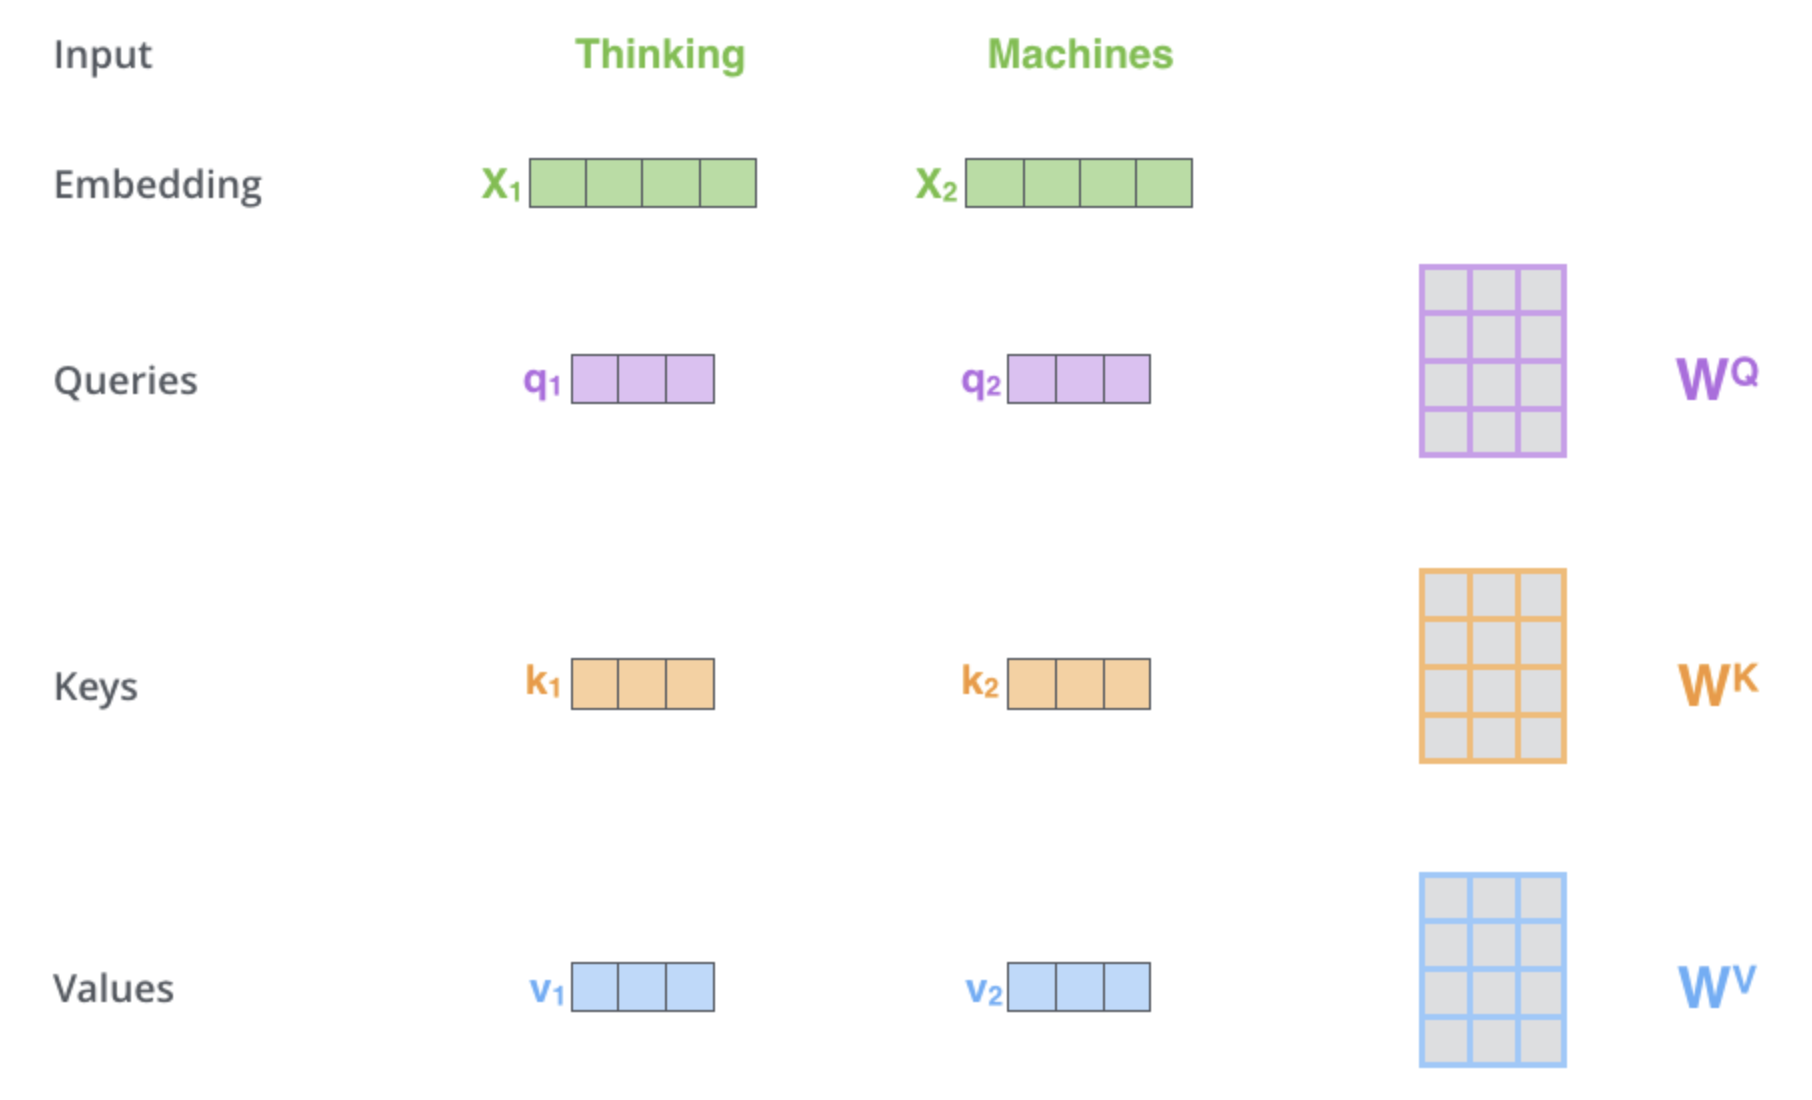

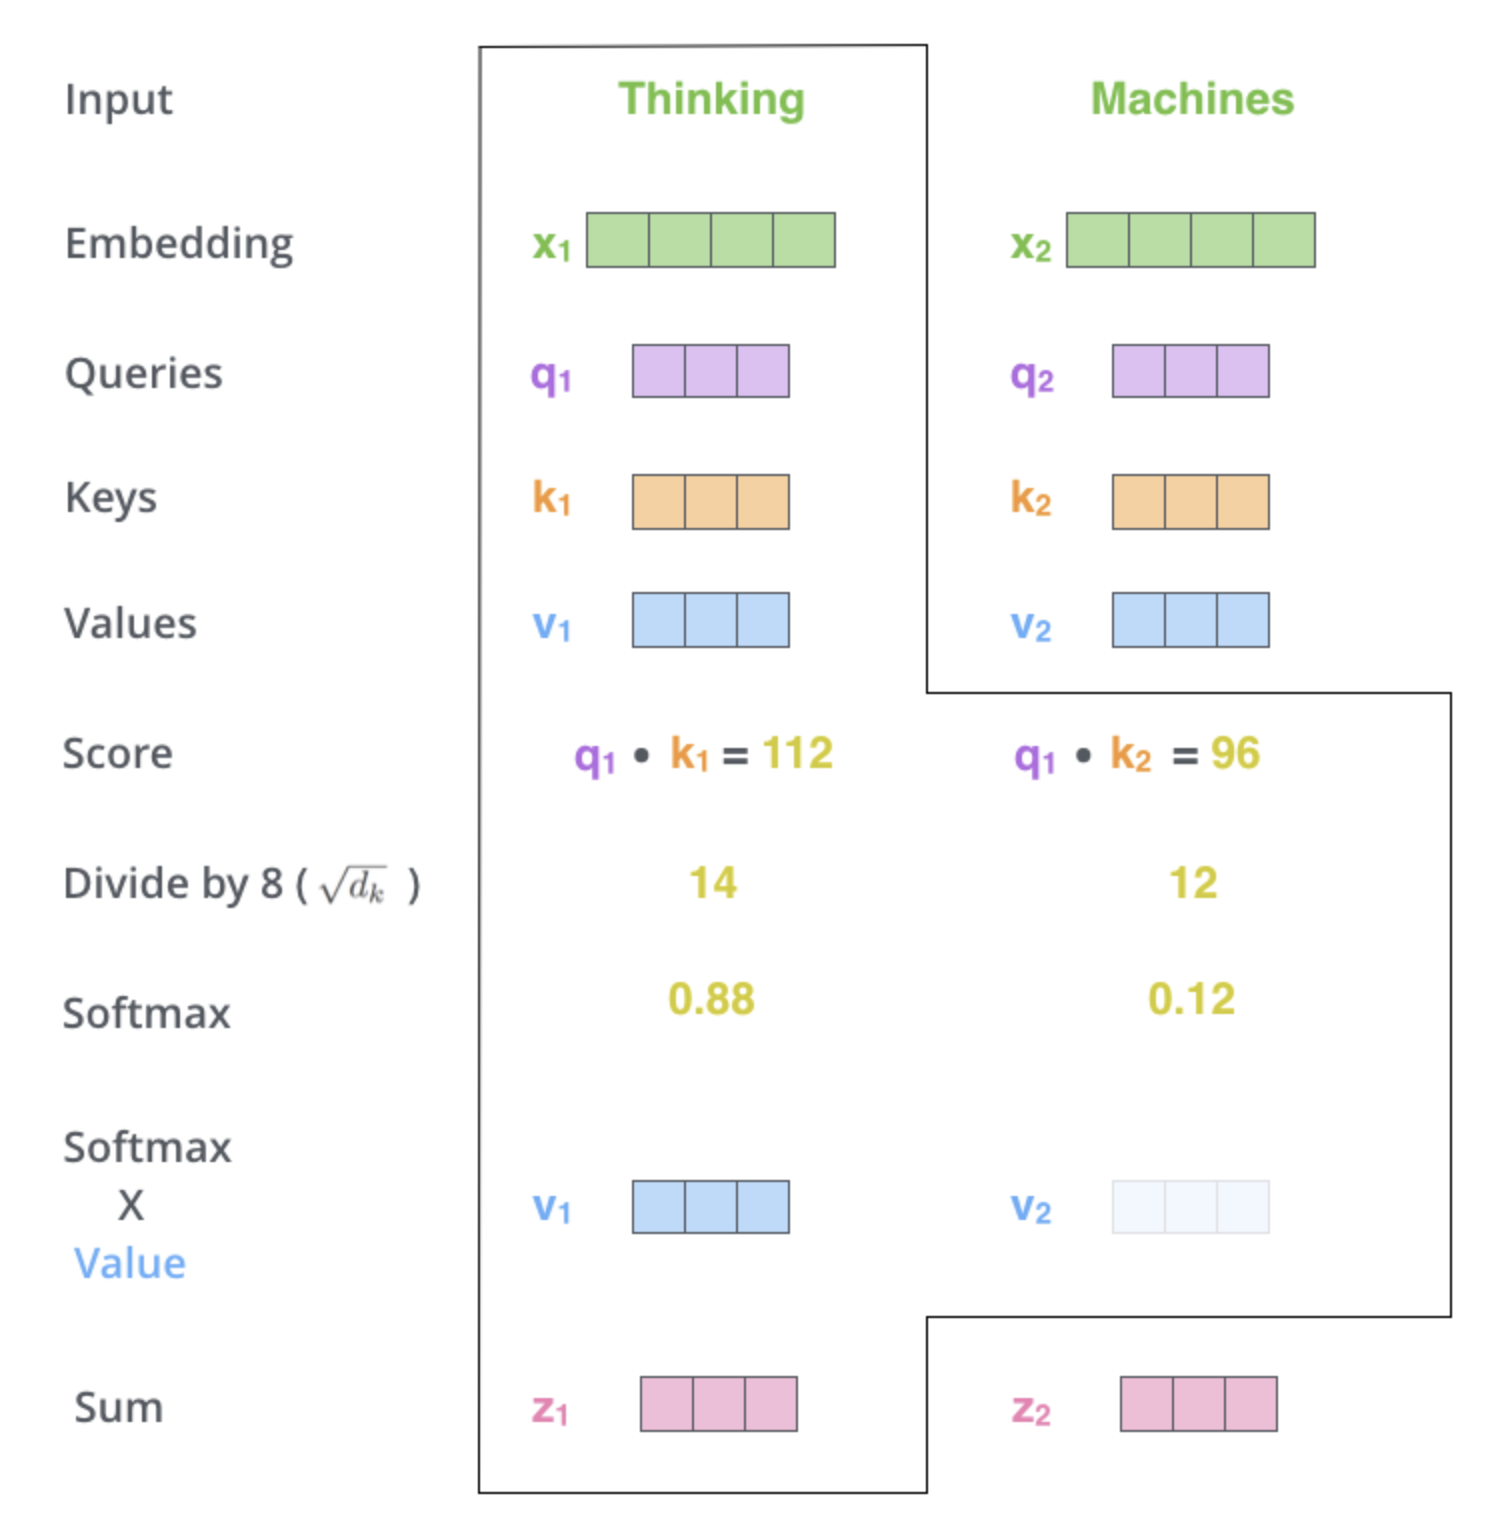

Attention в матричной форме:

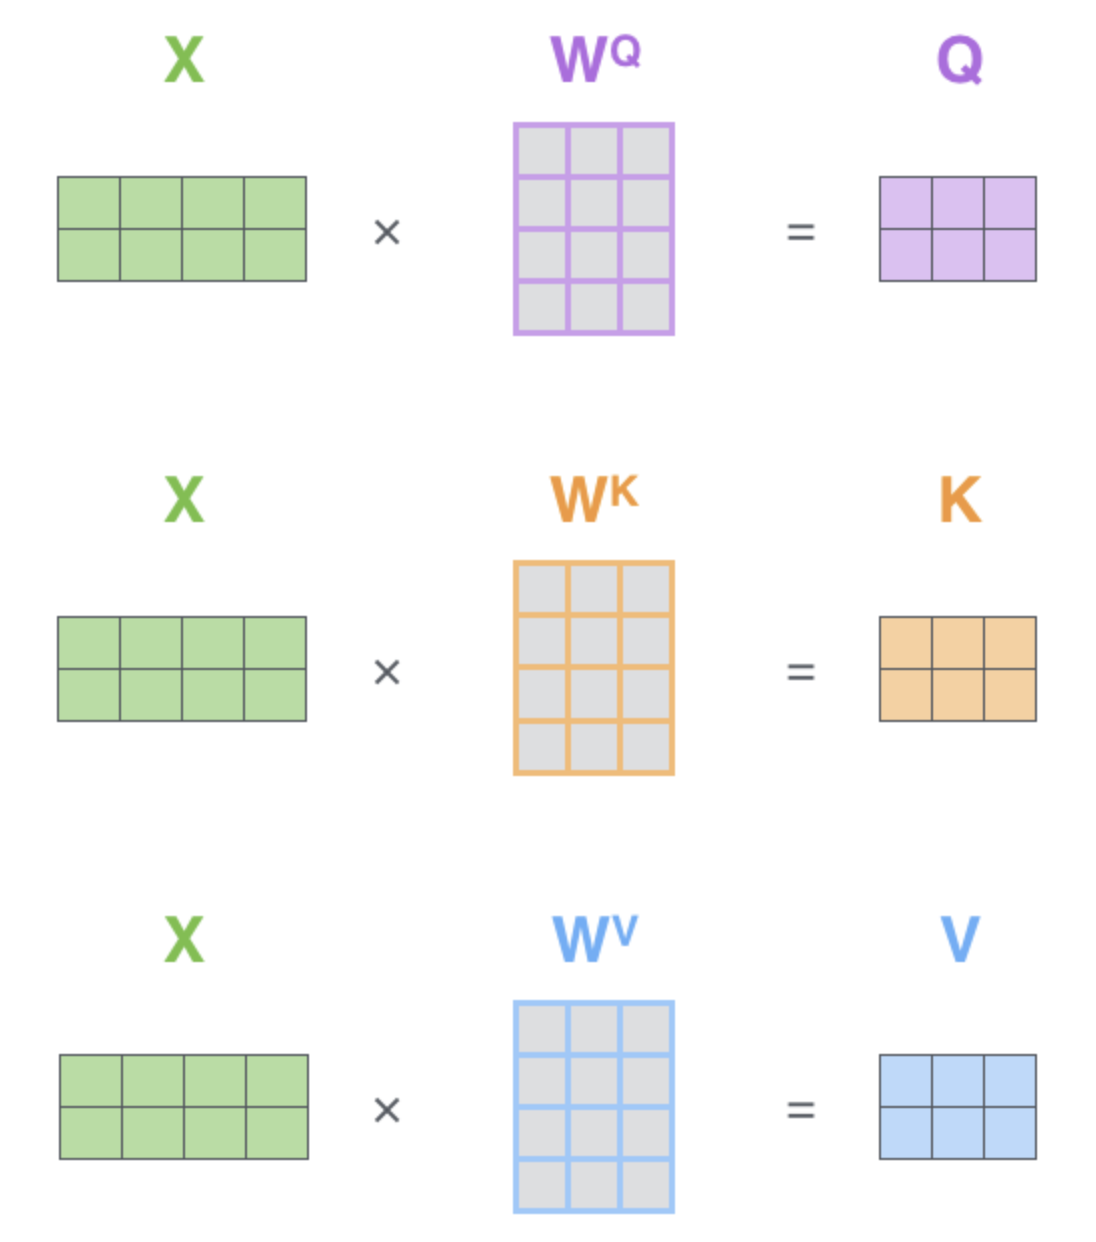

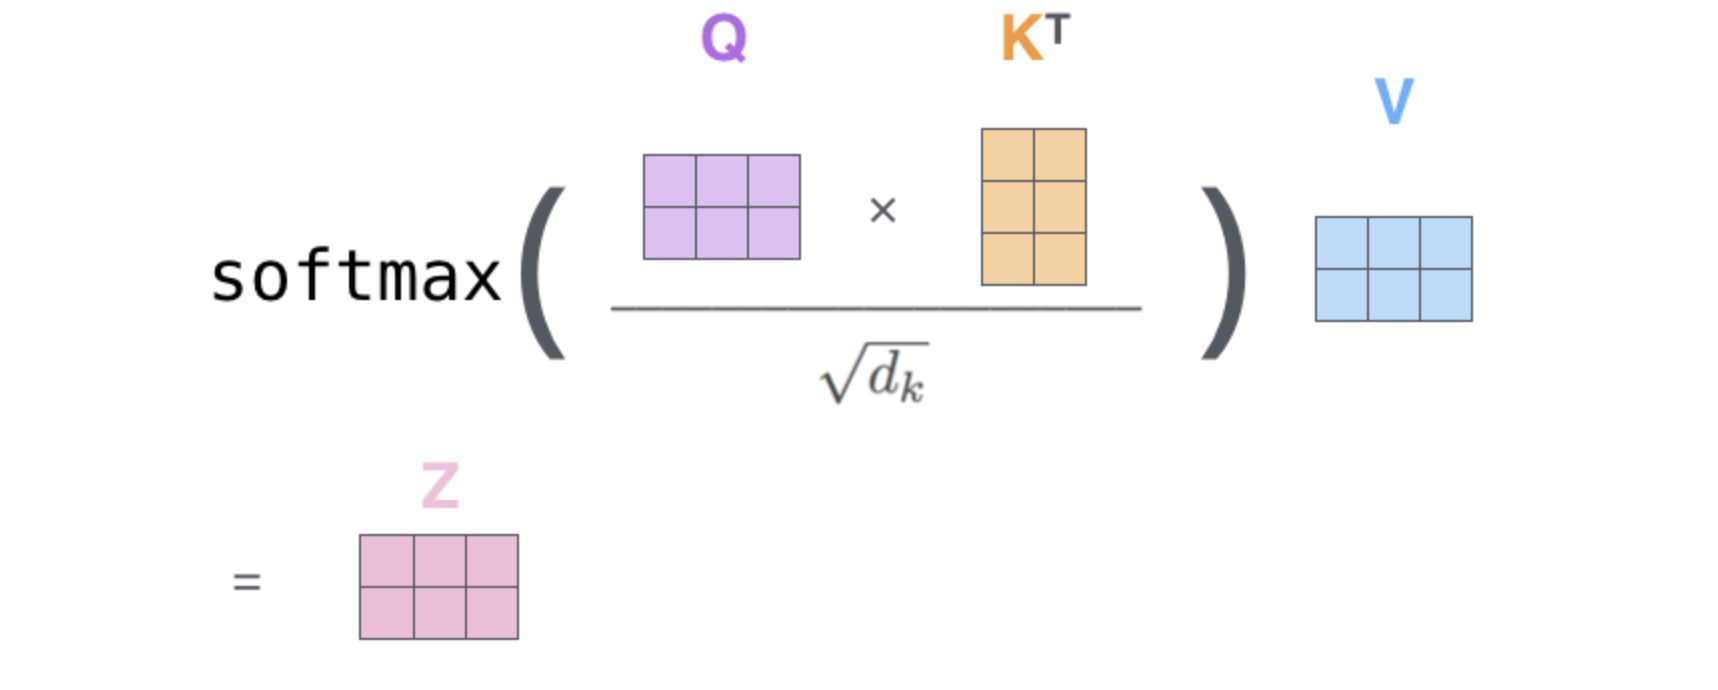

Attention :)

In [1]:
import math
import torch
import torch.nn.functional as F

def attention(queries, keys, values, Q, K, V, mask=None):
    # Входные тензоры имеют размерность: (batch_size, length, emb_size)
    # Маска имеет размерность: (batch_size, q_length, k_length)
    # Q, K и V — линейные слои (Projection layers): emb_size -> emb_size

    # Получаем размерность эмбеддинга (d_k) из последнего измерения тензора
    emb_size = queries.size(-1)

    # Линейное проецирование входных векторов в пространства Запросов (Queries), Ключей (Keys) и Значений (Values)
    # Размерности остаются прежними: (batch_size, length, emb_size)
    queries = Q(queries)
    keys = K(keys)
    values = V(values)

    # 1. Скалярное произведение Queries и Keys с масштабированием (Scaled Dot-Product)
    # Транспонируем последние две размерности keys: (batch_size, emb_size, k_length)
    # Результат матричного умножения: (batch_size, q_length, k_length)
    # Деление на sqrt(emb_size) стабилизирует градиенты при больших размерностях
    query_key_connection = torch.matmul(queries, keys.transpose(-1, -2)) / math.sqrt(emb_size)

    # 2. Применение маски (если она передана)
    # Заменяем элементы, где mask == 0, на минус бесконечность (-inf)
    # Это нужно, чтобы после Softmax эти связи занулились (например, для маскирования будущих токенов в декодере)
    if mask is not None:
        query_key_connection = query_key_connection.masked_fill(mask == 0, -torch.inf)

    # 3. Нормализация весов внимания (Softmax)
    # Применяется по последней оси (-1), превращая логиты в вероятностное распределение
    # Размерность: (batch_size, q_length, k_length)
    normalized_query_key = F.softmax(query_key_connection, -1)

    # 4. Взвешенное суммирование значений (Values)
    # Умножаем матрицу весов внимания на матрицу значений Values
    # Размерность результата: (batch_size, q_length, emb_size)
    reweighted_values = torch.matmul(normalized_query_key, values)

    # Возвращаем обновленные представления векторов и саму матрицу весов внимания (для визуализации)
    return reweighted_values, normalized_query_key


In [45]:
# batch_size, length, emb_size
queries = torch.randn((2, 5, 32))
keys = torch.randn((2, 5, 32))
values = torch.randn((2, 5, 32))

Q = nn.Linear(32, 32)
K = nn.Linear(32, 32)
V = nn.Linear(32, 32)
proj = nn.Linear(32, 32)

mask = torch.ones((2, 5, 5))

In [ ]:

attention_score, weights = attention(queries, keys, values, Q, K, V, mask)
attention_score.shape


torch.Size([2, 5, 32])

### 5. Decoder with attention.

Вектор контекста, согласно задумке, должен закодировать в себе всю информацию о входном предложении, достаточную чтобы совершить полный перевод.

Давайте придумаем какой-нибудь подход, чтобы, во-первых, модель могла пользоваться еще и промежуточными выходами `Encoder`а, а во-вторых, дадим возможность модели выбирать, какая именно часть изначального предложения ей нужна в эту секунду, чтобы сгенерировать именно это конкретное слово. Для этого воспользуемся механизмом, который называется `Attention`.

`Attention` позволяет декодеру "сфокусироваться" на разных выходах `Encoder`а, собирая из них дополнительную информацию.

Промежуточные выходы `Encoder` это те же самые `hidden_state`, просто выданные моделью на этапе, когда она еще не посмотрела на всю последовательность.

Информация оттуда относится только к какой-то части последовательности, зато она еще более свежая, не "затертая" последующими итерациями.

Если бы наш `Decoder` мог бы как-то догадаться, какая часть промежуточных выходов `Encoder` была бы ему наиболее полезна, он был бы очень доволен.

К счастью, мы занимаемся глубоким обучением, а значит, нам ничего не надо придумывать самим. Просто зададим саму операцию "внимания", а дальше наша модель выучит самостоятельно, как ей лучше пользоваться. Мы лишь даем ей инструмент, все остальное она выучивает сама, пользуясь методом обратного распространения ошибки.

In [49]:
import torch.nn as nn

class AttentionBlock(nn.Module):
    """
    Модуль PyTorch, объединяющий линейные слои проекций
    и вычисление механизма Scaled Dot-Product Attention.
    """
    def __init__(self, emb_size=128):
        super().__init__()
        # Инициализация обучаемых линейных слоев (W_Q, W_K, W_V)
        # Каждый слой проецирует вектор из пространства emb_size в это же пространство
        self.Q = nn.Linear(emb_size, emb_size)  # Слой для генерации Запросов (Queries)
        self.K = nn.Linear(emb_size, emb_size)  # Слой для генерации Ключей (Keys)
        self.V = nn.Linear(emb_size, emb_size)  # Слой для генерации Значений (Values)

    def forward(self, queries, keys, values, mask=None):
        """
        Прямой проход (Forward Pass) блока внимания.

        Аргументы:
            queries, keys, values: Входные тензоры размерности (batch_size, length, emb_size)
            mask: Опциональная маска размерности (batch_size, q_length, k_length)

        Возвращает:
            context: Взвешенная сумма значений (Values) с учетом весов внимания.
                     Размерность: (batch_size, q_length, emb_size)
            weights: Матрица весов внимания (после Softmax).
                     Размерность: (batch_size, q_length, k_length)
        """
        # Вызываем внешнюю функцию attention, передавая в неё входные данные,
        # созданные линейные слои (self.Q, self.K, self.V) и маску
        context, weights = attention(queries, keys, values, self.Q, self.K, self.V, mask)

        # Возвращаем результат вычисления контекста и веса внимания
        return context, weights


In [46]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class AttnDecoderRNN(nn.Module):
    """
    Рекуррентный декодер (на базе GRU) с механизмом внимания (AttentionBlock)
    для задач Seq2Seq (например, машинный перевод).
    """
    def __init__(self, hidden_size, output_size, dropout_p=0.1):
        super(AttnDecoderRNN, self).__init__()
        # Эмбеддинг для входных токенов декодера (размер словаря output_size -> вектор hidden_size)
        self.embedding = nn.Embedding(output_size, hidden_size)

        # Блок внимания, использующий скрытое состояние как Query, а выходы энкодера как Key и Value
        self.attention = AttentionBlock(hidden_size)

        # GRU принимает сконкатенированный вектор: [эмбеддинг токена + вектор контекста внимания]
        # Поэтому входной размер равен 2 * hidden_size
        self.gru = nn.GRU(2 * hidden_size, hidden_size, batch_first=True)

        # Линейный слой для предсказания распределения вероятностей следующего слова
        self.out = nn.Linear(hidden_size, output_size)

        # Регуляризация Dropout для предотвращения переобучения
        self.dropout = nn.Dropout(dropout_p)

    def forward(self, encoder_outputs, encoder_hidden, target_tensor=None):
        """
        Полный цикл генерации последовательности (прямой проход).
        """
        batch_size = encoder_outputs.size(0)

        # Инициализируем стартовый вход декодера токеном SOS (Start Of Sequence) для всего батча. Размеры: (batch_size, 1)
        decoder_input = torch.empty(batch_size, 1, dtype=torch.long, device=device).fill_(SOS_token)

        # Начальное скрытое состояние декодера — это последнее скрытое состояние энкодера
        decoder_hidden = encoder_hidden

        # Списки для сохранения выходов и весов внимания на каждом шаге генерации
        decoder_outputs = []
        attentions = []

        # Цикл генерации по времени до максимальной длины MAX_LENGTH
        for i in range(MAX_LENGTH):
            # Делаем один шаг генерации для текущего временного шага
            decoder_output, decoder_hidden, attn_weights = self.forward_step(
                decoder_input, decoder_hidden, encoder_outputs
            )
            # Сохраняем логиты предсказания и веса внимания текущего шага
            decoder_outputs.append(decoder_output)
            attentions.append(attn_weights)

            if target_tensor is not None:
                # Режим Teacher Forcing: передаем истинный следующий токен из датасета в качестве входа для следующего шага.
                # Извлекаем i-й токен и добавляем ось длины: (batch_size) -> (batch_size, 1)
                decoder_input = target_tensor[:, i].unsqueeze(1)
            else:
                # Без Teacher Forcing: сеть использует свое собственное предсказание
                # Находим индекс токена с максимальной вероятностью (жадное декодирование)
                _, topi = decoder_output.topk(1)
                # Убираем лишнюю размерность логитов и отвязываем тензор от графа вычислений (detach),
                # чтобы градиенты не текли через дискретный выбор токена
                decoder_input = topi.squeeze(-1).detach()

        # Объединяем выходы со всех шагов по оси времени (dim=1). Итог: (batch_size, MAX_LENGTH, output_size)
        decoder_outputs = torch.cat(decoder_outputs, dim=1)

        # Превращаем выходы в логарифмы вероятностей (удобно для функции потерь NLLLoss)
        decoder_outputs = F.log_softmax(decoder_outputs, dim=-1)

        # Объединяем матрицы внимания по оси времени. Итог: (batch_size, MAX_LENGTH, encoder_length)
        attentions = torch.cat(attentions, dim=1)

        return decoder_outputs, decoder_hidden, attentions


    def forward_step(self, input, hidden, encoder_outputs):
        """
        Один шаг (один токен) работы декодера.
        """
        # Переводим индекс токена в эмбеддинг и применяем Dropout. Размерность: (batch_size, 1, hidden_size)
        embedded = self.dropout(self.embedding(input))

        # Текущее скрытое состояние GRU имеет размер (num_layers, batch_size, hidden_size).
        # Меняем оси местами для блока внимания, делая его Query. Размерность: (batch_size, 1, hidden_size)
        query = hidden.permute(1, 0, 2)

        # Считаем внимание: ищем по Query (состояние декодера) в Keys/Values (выходы энкодера)
        # context: (batch_size, 1, hidden_size), attn_weights: (batch_size, 1, encoder_length)
        context, attn_weights = self.attention(query, encoder_outputs, encoder_outputs)

        # Конкатенируем эмбеддинг текущего слова и контекст внимания по последней оси.
        # Размерность становится: (batch_size, 1, 2 * hidden_size)
        input_gru = torch.cat((embedded, context), dim=2)

        # Пропускаем через GRU. На выходе получаем обновленный output и новое скрытое состояние hidden
        output, hidden = self.gru(input_gru, hidden)

        # Проецируем выход GRU в размерность словаря, чтобы получить логиты токенов. Размерность: (batch_size, 1, output_size)
        output = self.out(output)

        return output, hidden, attn_weights


In [47]:
config = {
    'hidden_size':128,
    'enc_optimizer': torch.optim.AdamW,
    'enc_lr': 0.003,
    'dec_lr': 0.003,
    'dec_optimizer': torch.optim.AdamW,
    'criterion': torch.nn.NLLLoss,
    'n_epochs': 20,
    'tf_ratio': 0.7,
    'bidirectional': False
}

In [50]:
encoder = EncoderRNN(french.n_words, config['hidden_size'], bidirectional=config['bidirectional']).to(device)
decoder = AttnDecoderRNN(config['hidden_size'], english.n_words).to(device)

In [51]:
train(dataloader, encoder, decoder, config)

  5%|▌         | 1/20 [00:18<05:42, 18.00s/it]

epoch_loss: 2.3997418880462646


 10%|█         | 2/20 [00:35<05:15, 17.51s/it]

epoch_loss: 1.7344012260437012


 15%|█▌        | 3/20 [00:52<04:59, 17.62s/it]

...

epoch_loss: 0.4780721366405487


 95%|█████████▌| 19/20 [05:20<00:16, 16.73s/it]

epoch_loss: 0.4530239701271057


100%|██████████| 20/20 [05:38<00:00, 16.93s/it]

epoch_loss: 0.45238545536994934
> vous etes tellement idiote !
= you are so stupid
< you re so stupid ! <EOS>



In [52]:
evaluate(encoder, decoder, 'je ne mange pas six jours', french, english)

(['i', 'm', 'not', 'eating', 'this', '<EOS>'],
 tensor([[[9.9985e-01, 1.4989e-04, 3.3908e-08, 5.9629e-08, 4.7662e-09,
           3.5707e-11, 2.6242e-11],
          [4.5696e-07, 2.9249e-05, 1.2508e-03, 2.6190e-04, 9.9420e-01,
           4.0002e-03, 2.6214e-04],
          [7.0533e-09, 1.0320e-01, 1.7936e-01, 7.1706e-01, 3.7713e-04,
           1.4024e-07, 6.9203e-09],
          [1.8454e-07, 2.1398e-04, 7.0962e-01, 3.5465e-03, 2.8659e-01,
           2.5975e-05, 3.8534e-07],
          [1.8951e-10, 1.0376e-09, 4.3073e-05, 3.3203e-05, 9.4067e-01,
           5.3006e-02, 6.2427e-03],
          [1.6592e-12, 6.2242e-12, 1.3818e-08, 6.1118e-08, 9.0277e-05,
           2.6821e-01, 7.3170e-01],
          [3.6633e-16, 1.3172e-13, 6.3540e-09, 2.9732e-07, 1.9806e-06,
           4.6139e-02, 9.5386e-01],
          [1.0363e-19, 2.0339e-16, 2.9345e-11, 1.5253e-09, 7.4635e-08,
           1.7238e-02, 9.8276e-01],
          [2.5488e-20, 3.3436e-16, 4.5303e-11, 6.3380e-10, 6.6073e-08,
           1.8075e-02, 9.8

input = il n est pas aussi grand que son pere
output = he is not as tall as his father <EOS>


/tmp/ipykernel_515/625712247.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([''] + input_sentence.split(' ') +
/tmp/ipykernel_515/625712247.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([''] + output_words)


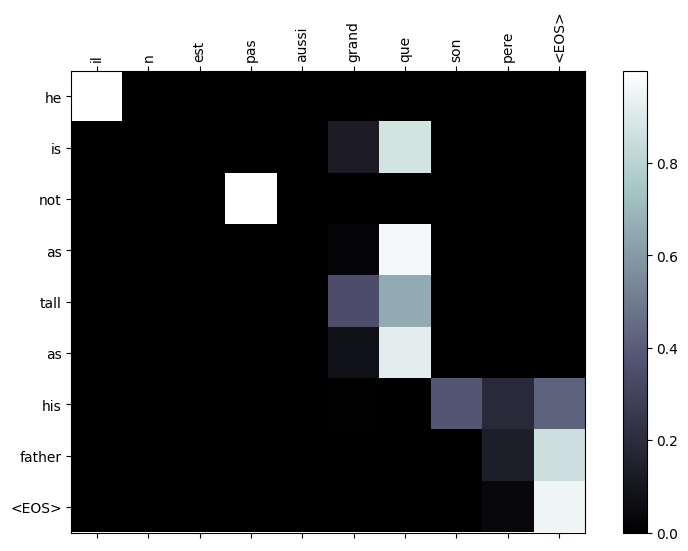

input = je suis trop fatigue pour conduire
output = i m too tired to drive happy <EOS>


/tmp/ipykernel_515/625712247.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([''] + input_sentence.split(' ') +
/tmp/ipykernel_515/625712247.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([''] + output_words)


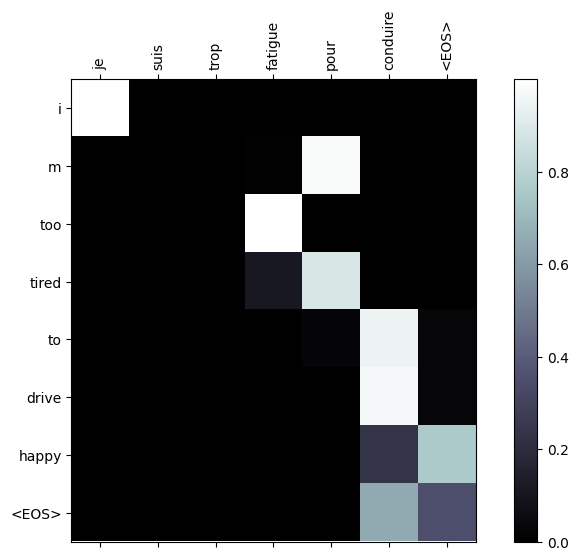

input = je suis desole si c est une question idiote
output = i m sorry if that stupid a question <EOS>


/tmp/ipykernel_515/625712247.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([''] + input_sentence.split(' ') +
/tmp/ipykernel_515/625712247.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([''] + output_words)


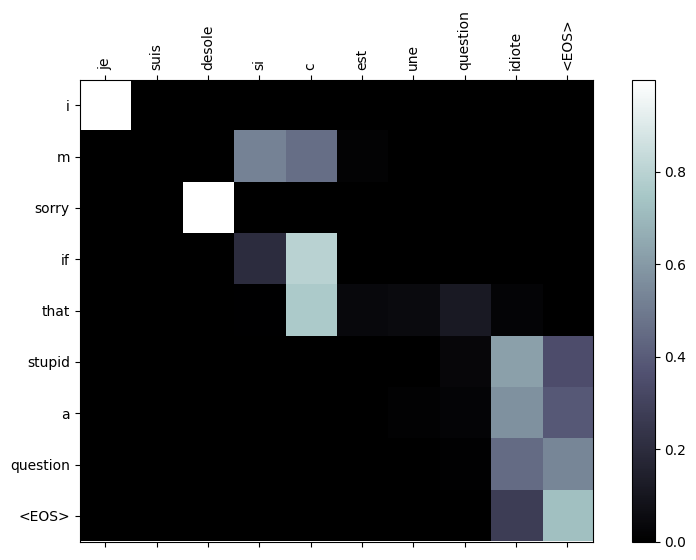

input = je suis reellement fiere de vous
output = i m really proud of you <EOS>


/tmp/ipykernel_515/625712247.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([''] + input_sentence.split(' ') +
/tmp/ipykernel_515/625712247.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([''] + output_words)


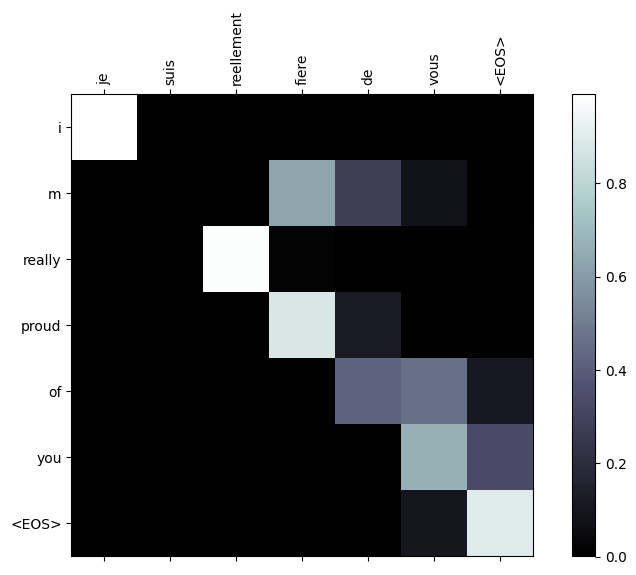

In [53]:
from matplotlib import ticker
def showAttention(input_sentence, output_words, attentions):
    fig = plt.figure()
    ax = fig.add_subplot(111)
    cax = ax.matshow(attentions.cpu().numpy(), cmap='bone')
    fig.colorbar(cax)

    # Set up axes
    ax.set_xticklabels([''] + input_sentence.split(' ') +
                       ['<EOS>'], rotation=90)
    ax.set_yticklabels([''] + output_words)

    # Show label at every tick
    ax.xaxis.set_major_locator(ticker.MultipleLocator(1))
    ax.yaxis.set_major_locator(ticker.MultipleLocator(1))

    plt.show()


def evaluateAndShowAttention(input_sentence):
    output_words, attentions = evaluate(encoder, decoder, input_sentence, french, english)
    print('input =', input_sentence)
    print('output =', ' '.join(output_words))
    showAttention(input_sentence, output_words, attentions[0, :len(output_words), :])


evaluateAndShowAttention('il n est pas aussi grand que son pere')

evaluateAndShowAttention('je suis trop fatigue pour conduire')

evaluateAndShowAttention('je suis desole si c est une question idiote')

evaluateAndShowAttention('je suis reellement fiere de vous')